## Emotion Classification with RNNs, grus & GRUs

**1.Import Libraries**

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# help to load Dataset
from datasets import load_dataset

**2.Load Dataset**

In [2]:
emotion_dataset = load_dataset('dair-ai/emotion')
train_text      = emotion_dataset['train']['text']
train_label     = emotion_dataset['train']['label']

test_text       = emotion_dataset['test']['text']
test_label      = emotion_dataset['test']['label']

In [3]:
label_names = emotion_dataset['train'].features['label'].names

In [4]:
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [5]:
df_train = pd.DataFrame(
    {
        'text'  : train_text,
        'label' : [label_names[i] for i in train_label]
    }
)

df_test = pd.DataFrame(
    {
        'text' : test_text,
        'label' : [label_names[i] for i in test_label]
    }
)

In [6]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [7]:
df_train.isnull().sum()

text     0
label    0
dtype: int64

**3.Exploratory Data Analysis (EDA)**

In [8]:
df_train['label'].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='str', name='label')

<Axes: xlabel='label', ylabel='count'>

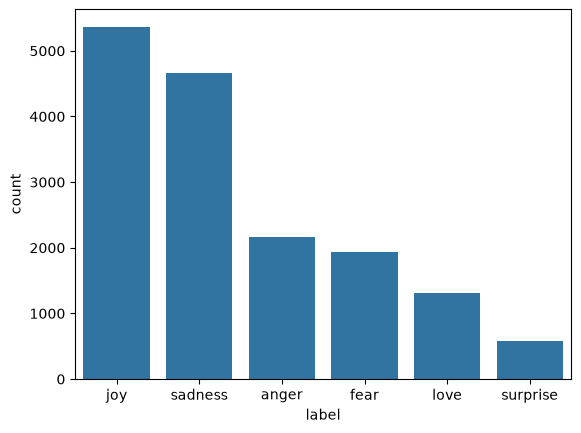

In [9]:
sns.countplot(x='label', data=df_train, order=df_train['label'].value_counts().index)

**4.Data Preprocessing - Using NLP**

In [10]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words = 10000

tokenizer = Tokenizer(num_words=max_words, oov_token='<unk>')
tokenizer.fit_on_texts(df_train['text'])

train_sequence = tokenizer.texts_to_sequences(df_train['text'])
test_sequence = tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequence = pad_sequences(train_sequence, maxlen=50, padding='post', truncating='post')
padded_test_sequence = pad_sequences(test_sequence, maxlen=50, padding='post', truncating='post')

train_labels = np.array(train_label)
test_labels = np.array(test_label)

num_classes = len(np.unique(train_labels))
num_classes

print(f"Volcabulary Size: {len(tokenizer.word_index)}")
print(f"Max Sentence Length: {padded_train_sequence.shape[1]}")

Volcabulary Size: 15213
Max Sentence Length: 50


**5.Shared Training Utilities**

In [11]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight = 'balanced',
    classes      = np.unique(train_labels),
    y            = train_labels
)

class_weight_dict = dict(enumerate(class_weights))

In [12]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

**6.Phase 1 - Plain Foundational Models**

**6.1 Model 1 - Simple RNN**

In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Embedding, Dense, Dropout, LSTM, GRU

rnn_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=50),
    SimpleRNN(units=128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
])

rnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [14]:
rnn_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequence, test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 39ms/step - accuracy: 0.1598 - loss: 1.9214 - val_accuracy: 0.1160 - val_loss: 1.8237
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 38ms/step - accuracy: 0.1528 - loss: 1.8090 - val_accuracy: 0.2255 - val_loss: 1.7744
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - accuracy: 0.1689 - loss: 1.7887 - val_accuracy: 0.1205 - val_loss: 1.8015
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - accuracy: 0.1598 - loss: 1.7761 - val_accuracy: 0.1235 - val_loss: 1.7924
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - accuracy: 0.1604 - loss: 1.7663 - val_accuracy: 0.1145 - val_loss: 1.7831
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.2255 - loss: 1.7744
RNN Loss: 1.774351954460144
RNN Accuracy: 0.22550000250339508


**6.2 Model 2 - Standard lstm**

In [15]:
lstm_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=50),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
])

lstm_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequence, test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 52s 97ms/step - accuracy: 0.1515 - loss: 1.7958 - val_accuracy: 0.0980 - val_loss: 1.7977
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 58s 115ms/step - accuracy: 0.1505 - loss: 1.7935 - val_accuracy: 0.0825 - val_loss: 1.7916
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 54s 109ms/step - accuracy: 0.1363 - loss: 1.7935 - val_accuracy: 0.0495 - val_loss: 1.7998
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 39s 77ms/step - accuracy: 0.1406 - loss: 1.7904 - val_accuracy: 0.1445 - val_loss: 1.7673
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 40s 79ms/step - accuracy: 0.1712 - loss: 1.7704 - val_accuracy: 0.0840 - val_loss: 1.8104
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 82ms/step - accuracy: 0.1854 - loss: 1.6866 - val_accuracy: 0.1790 - val_loss: 1.8088
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 82ms/step - accuracy: 0.3349 - loss: 1.4596 - val_accuracy: 0.3445 - val_loss: 1.5374
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 38s 75ms/step - accuracy: 0.4816 - loss: 1.1660 

**6.3 Model 3 - Standard GRU**

In [16]:
gru_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=50),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
])

gru_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

gru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequence, test_labels)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 62s 116ms/step - accuracy: 0.1562 - loss: 1.7975 - val_accuracy: 0.3430 - val_loss: 1.7863
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 53s 106ms/step - accuracy: 0.1651 - loss: 1.7946 - val_accuracy: 0.2850 - val_loss: 1.7879
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 51s 103ms/step - accuracy: 0.1359 - loss: 1.7946 - val_accuracy: 0.0335 - val_loss: 1.8115
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 36s 73ms/step - accuracy: 0.1636 - loss: 1.7938 - val_accuracy: 0.0830 - val_loss: 1.8010
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.3430 - loss: 1.7863
GRU Loss: 1.786335825920105
GRU Accuracy: 0.34299999475479126


**6.4 Phase 1 Ranking & Selection**

In [17]:
result_df = pd.DataFrame({
    'Model' : ['RNN', 'LSTM', 'GRU'],
    'Test Loss' : [rnn_loss, lstm_loss, gru_loss],
    'Test Accuracy' : [rnn_accuracy, lstm_accuracy, gru_accuracy ]
})
result_df

,Model,Test Loss,Test Accuracy
0,RNN,1.774352,0.2255
1,LSTM,0.452642,0.8765
2,GRU,1.786336,0.3430


**7.Phase 2 - Advanced Bidirectional GRU**

**7.1 Model 4 - Advanced Stacked Bidirectional GRU**

In [19]:
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
    Embedding(input_dim=max_words, output_dim=300, input_length=50),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

BiGRU.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

BiGRU.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
BiGRU.fit(
    padded_train_sequence,
        train_labels,
        validation_data=(padded_test_sequence, test_labels),
        epochs=20,
        batch_size=32,
        class_weight=class_weight_dict,
        callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 83s 147ms/step - accuracy: 0.5671 - loss: 1.0502 - val_accuracy: 0.8770 - val_loss: 0.4096
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 64s 127ms/step - accuracy: 0.9075 - loss: 0.2702 - val_accuracy: 0.8930 - val_loss: 0.3109
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 58s 115ms/step - accuracy: 0.9347 - loss: 0.1735 - val_accuracy: 0.9120 - val_loss: 0.2527
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 59s 117ms/step - accuracy: 0.9517 - loss: 0.1325 - val_accuracy: 0.9195 - val_loss: 0.2484
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 60s 119ms/step - accuracy: 0.9627 - loss: 0.1001 - val_accuracy: 0.9170 - val_loss: 0.3027
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 54s 107ms/step - accuracy: 0.9740 - loss: 0.0727 - val_accuracy: 0.9190 - val_loss: 0.2743
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 55s 110ms/step - accuracy: 0.9774 - loss: 0.0602 - val_accuracy: 0.9085 - val_loss: 0.3711


In [21]:
BiGRU_loss, BiGRU_accuracy = BiGRU.evaluate(padded_test_sequence, test_labels)
print(f"BiGRU Loss: {BiGRU_loss}")
print(f"BiGRU Accuracy: {BiGRU_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.9195 - loss: 0.2484
BiGRU Loss: 0.24842527508735657
BiGRU Accuracy: 0.9194999933242798


**8.Overall Evalution & Bias Analysis**

**8.1 Final Model Confusion Matrices (Raw Counts & Normalized%)**

63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step


<Axes: >

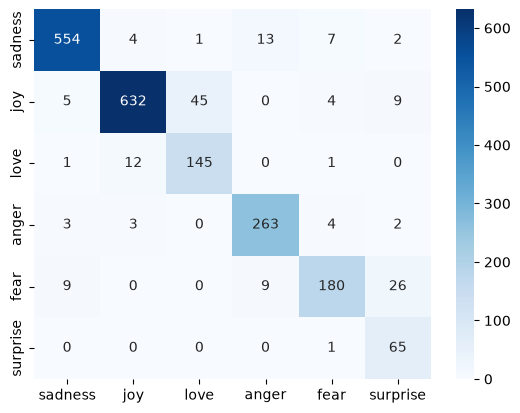

In [26]:
from sklearn.metrics import confusion_matrix

BiGRU_prediction = np.argmax(BiGRU.predict(padded_test_sequence), axis=1)

sns.heatmap(confusion_matrix(test_label, BiGRU_prediction),annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)

**9.Final Predicitons**

In [35]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark always alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_prediction = np.argmax(BiGRU.predict(sample_padded_sequences),axis=1)

for i in range(len(sample_texts)):
    print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_prediction[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: surprise
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark always alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


**10.Save Model & Tokenizer**

In [40]:
import os
import pickle

model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True) #Create folder

#Save our BiGRU Model
BiGRU.save(os.path.join(model_dir, 'BiGRU_Model.keras'))

#Save the Tokenizer model
with open(os.path.join(model_dir, 'tokenizer.pkl'),'wb') as file:
    pickle.dump(tokenizer, file)